Mounted at /content/drive
Found 9 grid CSV files for processing.


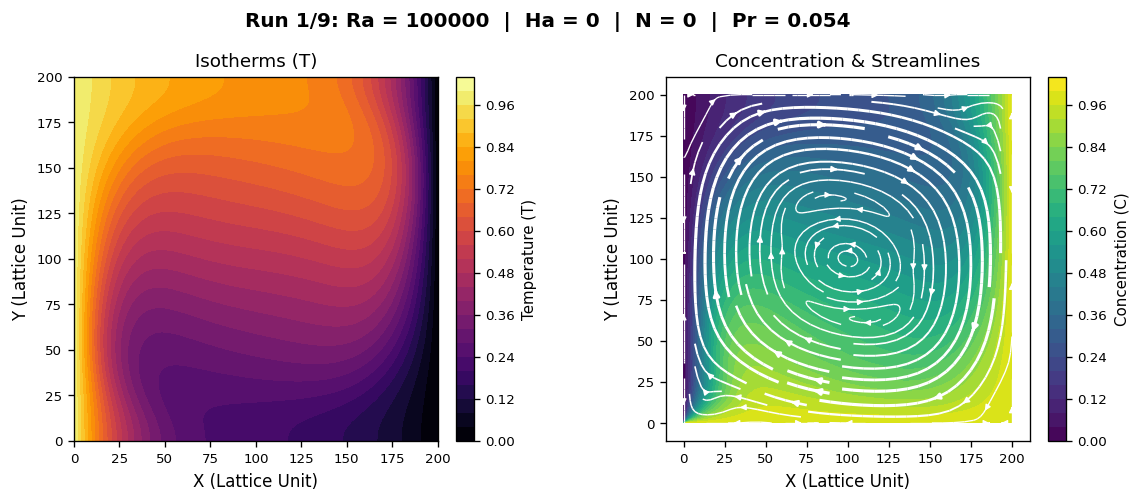

[1/9] Saved image to Drive: grid_Ra100000_Ha0_N0_Pr0.054_plots.png


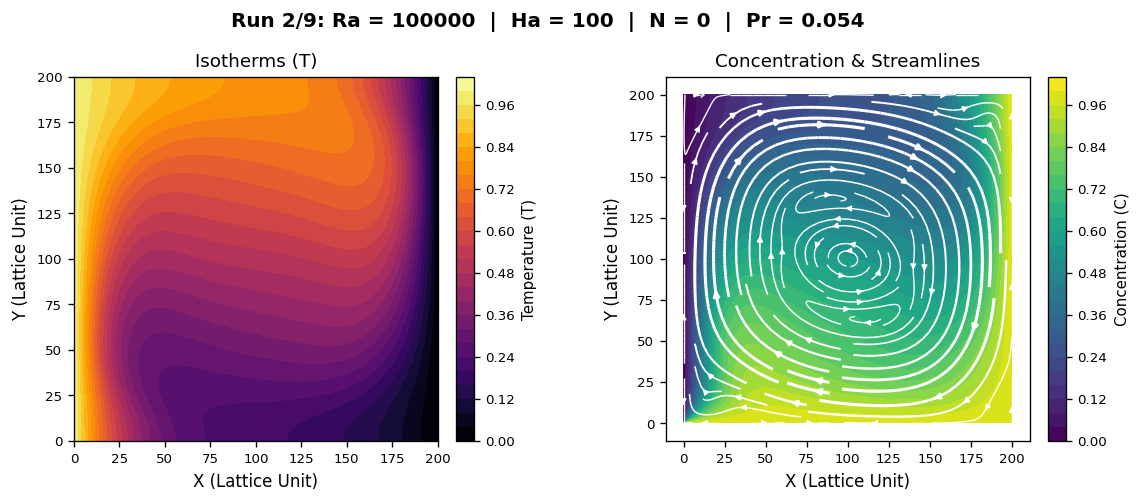

[2/9] Saved image to Drive: grid_Ra100000_Ha100_N0_Pr0.054_plots.png


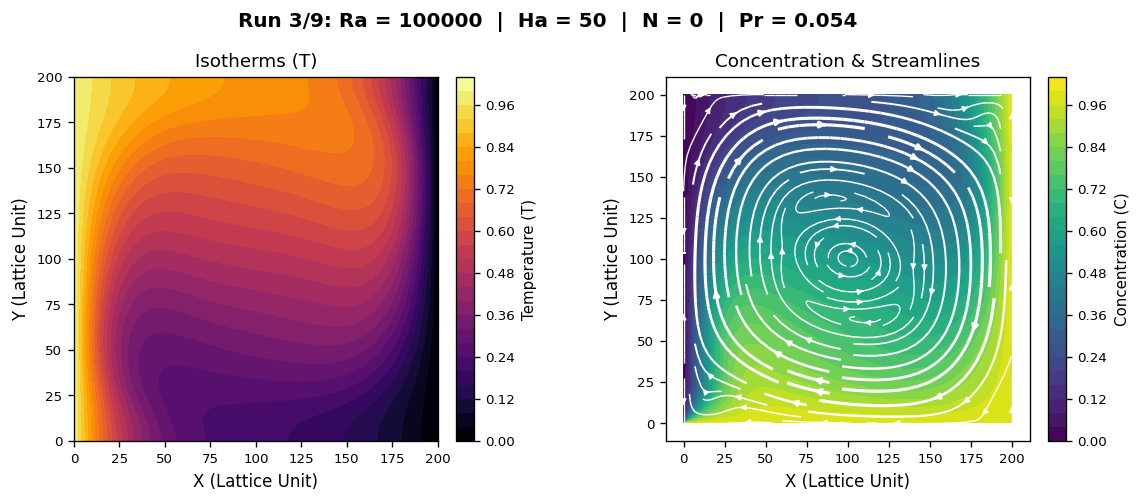

[3/9] Saved image to Drive: grid_Ra100000_Ha50_N0_Pr0.054_plots.png


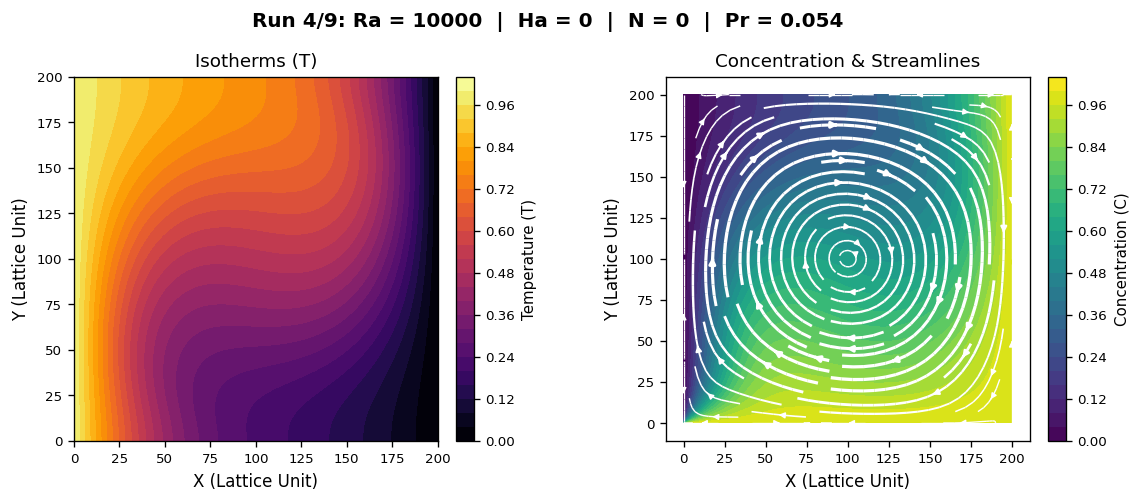

[4/9] Saved image to Drive: grid_Ra10000_Ha0_N0_Pr0.054_plots.png


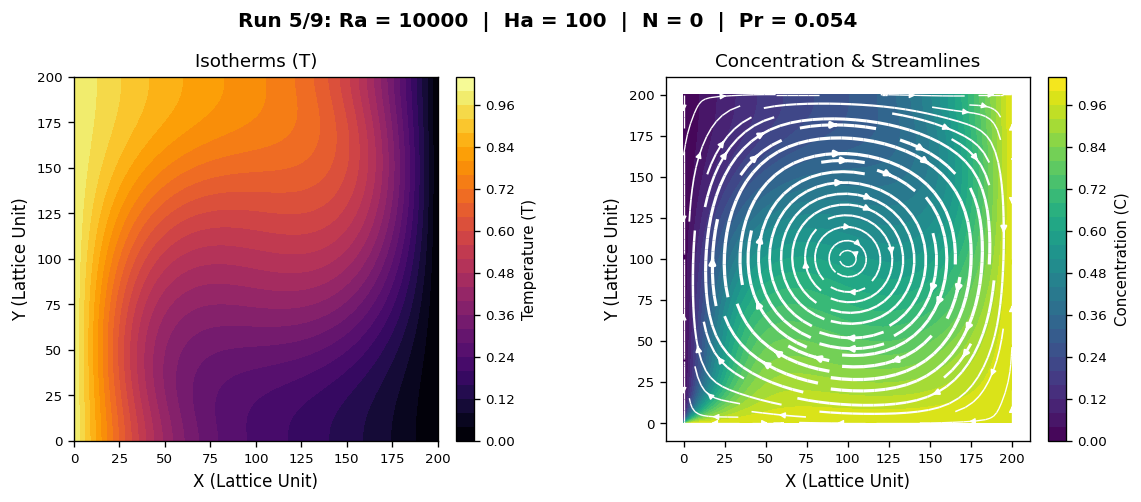

[5/9] Saved image to Drive: grid_Ra10000_Ha100_N0_Pr0.054_plots.png


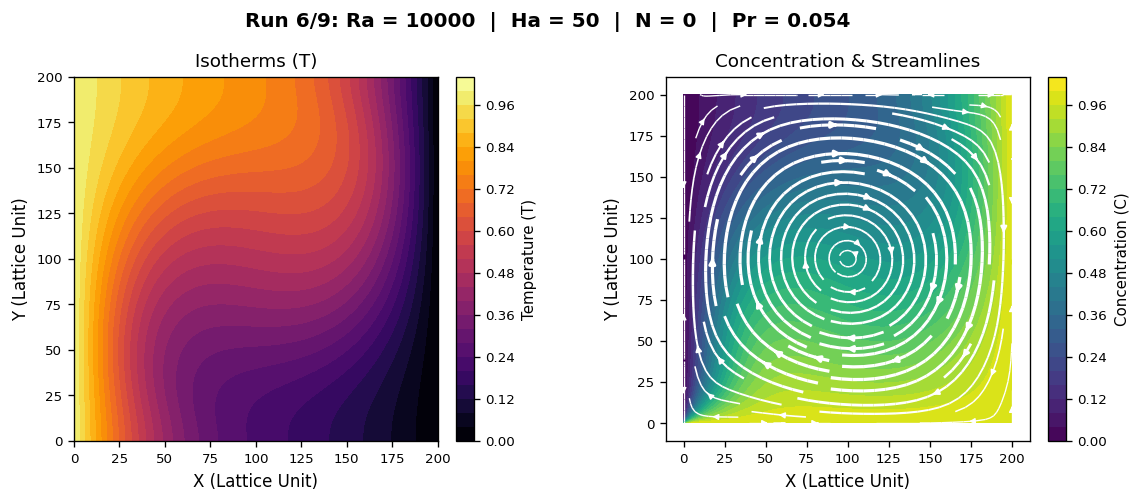

[6/9] Saved image to Drive: grid_Ra10000_Ha50_N0_Pr0.054_plots.png


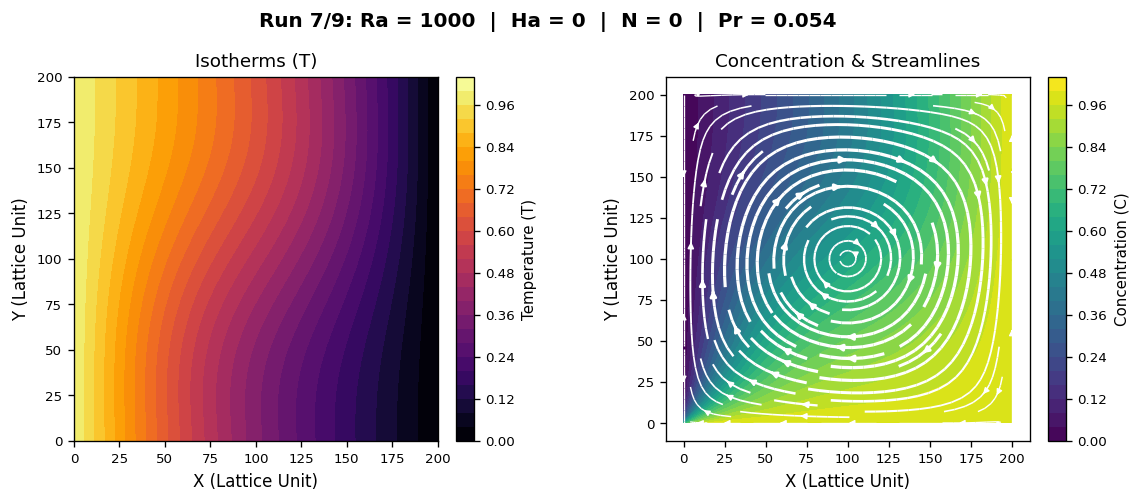

[7/9] Saved image to Drive: grid_Ra1000_Ha0_N0_Pr0.054_plots.png


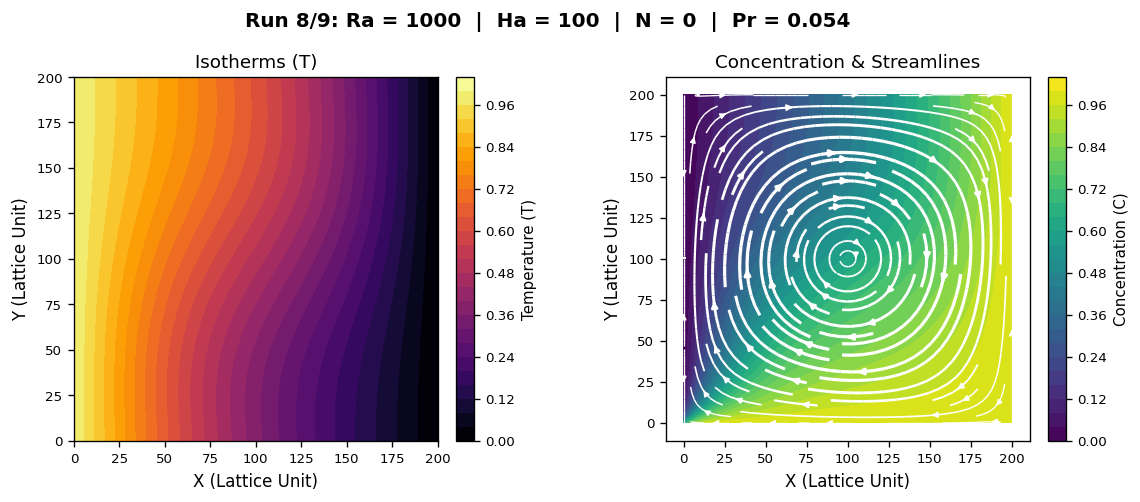

[8/9] Saved image to Drive: grid_Ra1000_Ha100_N0_Pr0.054_plots.png


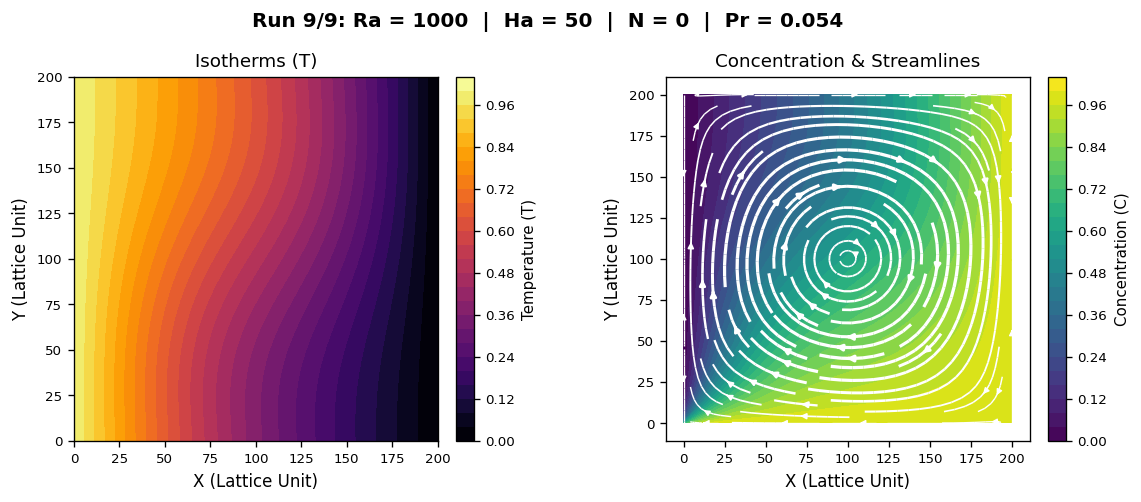

[9/9] Saved image to Drive: grid_Ra1000_Ha50_N0_Pr0.054_plots.png

All plots generated and saved directly to Drive in: /content/drive/MyDrive/BTP_project/plots_Ra_Ha_study


In [1]:
import os
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Define Input Data Path and Output Drive Path
data_dir = '/content/drive/MyDrive/BTP_project/output_csv_data_Ra Ha Study'
output_dir = '/content/drive/MyDrive/BTP_project/plots_Ra_Ha_study'

# Create the output plots folder directly inside BTP_project on Google Drive
os.makedirs(output_dir, exist_ok=True)

# Find all grid CSV files
csv_files = sorted(
    [f for f in os.listdir(data_dir) if f.startswith('grid_') and f.endswith('.csv')]
)
print(f'Found {len(csv_files)} grid CSV files for processing.')


# Function to extract parameter values from grid filenames
def parse_filename(filename):
  pattern = (
      r'grid_Ra([\d\.eE+-]+)_Ha([\d\.eE+-]+)_N([\d\.eE+-]+)_Pr([\d\.eE+-]+)\.csv'
  )
  match = re.search(pattern, filename)
  if match:
    return {
        'Ra': match.group(1),
        'Ha': match.group(2),
        'N': match.group(3),
        'Pr': match.group(4),
    }
  return {'Ra': 'N/A', 'Ha': 'N/A', 'N': 'N/A', 'Pr': 'N/A'}


# Global compact plot styling
plt.rcParams.update({
    'font.sans-serif': 'DejaVu Sans',
    'font.family': 'sans-serif',
    'font.size': 9,
    'axes.labelsize': 10,
    'axes.titlesize': 11,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'figure.titlesize': 12,
})

for idx, fname in enumerate(csv_files, 1):
  fpath = os.path.join(data_dir, fname)
  params = parse_filename(fname)

  df = pd.read_csv(fpath)

  # Reshape 1D flat grid into 2D spatial matrices
  nx = df['i'].nunique()
  ny = df['j'].nunique()

  X = df['i'].values.reshape((ny, nx))
  Y = df['j'].values.reshape((ny, nx))
  T = df['T'].values.reshape((ny, nx))
  C = df['C'].values.reshape((ny, nx))
  U = df['u'].values.reshape((ny, nx))
  V = df['v'].values.reshape((ny, nx))

  param_title = f"Ra = {params['Ra']}  |  Ha = {params['Ha']}  |  N = {params['N']}  |  Pr = {params['Pr']}"
  base_name = os.path.splitext(fname)[0]

  # Create side-by-side figure (Isotherms & Concentration with Streamlines)
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.2), dpi=120)
  fig.suptitle(
      f'Run {idx}/{len(csv_files)}: {param_title}', y=0.98, weight='bold'
  )

  # --- Plot 1: Isotherms (T) ---
  contour_t = ax1.contourf(X, Y, T, levels=25, cmap='inferno')
  cbar_t = fig.colorbar(contour_t, ax=ax1, fraction=0.046, pad=0.04)
  cbar_t.set_label('Temperature (T)', fontsize=9)
  ax1.set_title('Isotherms (T)')
  ax1.set_xlabel('X (Lattice Unit)')
  ax1.set_ylabel('Y (Lattice Unit)')
  ax1.set_aspect('equal', 'box')

  # --- Plot 2: Concentration (C) + Streamlines ---
  contour_c = ax2.contourf(X, Y, C, levels=25, cmap='viridis')
  cbar_c = fig.colorbar(contour_c, ax=ax2, fraction=0.046, pad=0.04)
  cbar_c.set_label('Concentration (C)', fontsize=9)

  speed = np.sqrt(U**2 + V**2)
  lw = 0.8 + 1.2 * (speed / (speed.max() if speed.max() > 0 else 1.0))
  ax2.streamplot(
      X[0, :],
      Y[:, 0],
      U,
      V,
      color='white',
      linewidth=lw,
      density=1.0,
      arrowsize=0.7,
  )

  ax2.set_title('Concentration & Streamlines')
  ax2.set_xlabel('X (Lattice Unit)')
  ax2.set_ylabel('Y (Lattice Unit)')
  ax2.set_aspect('equal', 'box')

  plt.tight_layout()

  # Save image directly into your Google Drive BTP_project/plots_Ra_Ha_study folder
  combined_img_path = os.path.join(output_dir, f'{base_name}_plots.png')
  plt.savefig(combined_img_path, bbox_inches='tight', dpi=300)

  plt.show()
  plt.close()

  print(f'[{idx}/{len(csv_files)}] Saved image to Drive: {base_name}_plots.png')

print(f'\nAll plots generated and saved directly to Drive in: {output_dir}')